In [ ]:
print('Hello_World')

Hello_World


#**Data Loading**

In [ ]:
from google.colab import files

files.upload()

Saving kaggle.json to kaggle (1).json


{'kaggle (1).json': b'{"username":"prashant017","key":"74bc2209ffee86ec7cb141e181ba2f8c"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!pip install -q kaggle

In [ ]:
!kaggle --version

Kaggle CLI 2.0.2


In [ ]:
!kaggle datasets download -d adityajn105/flickr8k

Dataset URL: https://www.kaggle.com/datasets/adityajn105/flickr8k
License(s): CC0-1.0
flickr8k.zip: Skipping, found more recently modified local copy (use --force to force download)


In [ ]:
!unzip -q flickr8k.zip -d /content/flickr8k

replace /content/flickr8k/Images/1000268201_693b08cb0e.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: A


In [ ]:
!ls /content/flickr8k

captions.txt  Images


In [ ]:
import os

image_dir = "/content/flickr8k/Images"

print("Number of images:", len(os.listdir(image_dir)))

Number of images: 8091


In [ ]:
images = os.listdir(image_dir)

print(images[:10])

['2661437618_ca7a15f3cb.jpg', '3079917032_3cfacb2fd7.jpg', '3201594926_cd2009eb13.jpg', '3486324591_9f5eeb24b9.jpg', '3538213870_9856a76b2a.jpg', '3354330935_de75be9d2f.jpg', '2525232298_cf42d415ab.jpg', '2911238432_33ec2d8cec.jpg', '2747640247_b54bfa6886.jpg', '429851331_b248ca01cd.jpg']


In [ ]:
import pandas as pd

captions_path = "/content/flickr8k/captions.txt"

df = pd.read_csv(captions_path)

df.head()

,image,caption
0,1000268201_693b08cb0e.jpg,A child in a pink dress is climbing up a set o...
1,1000268201_693b08cb0e.jpg,A girl going into a wooden building .
2,1000268201_693b08cb0e.jpg,A little girl climbing into a wooden playhouse .
3,1000268201_693b08cb0e.jpg,A little girl climbing the stairs to her playh...
4,1000268201_693b08cb0e.jpg,A little girl in a pink dress going into a woo...


In [ ]:
print(df.shape)
print(df.columns)

(40455, 2)
Index(['image', 'caption'], dtype='object')


In [ ]:
df.head(10)

,image,caption
0,1000268201_693b08cb0e.jpg,A child in a pink dress is climbing up a set o...
1,1000268201_693b08cb0e.jpg,A girl going into a wooden building .
2,1000268201_693b08cb0e.jpg,A little girl climbing into a wooden playhouse .
3,1000268201_693b08cb0e.jpg,A little girl climbing the stairs to her playh...
4,1000268201_693b08cb0e.jpg,A little girl in a pink dress going into a woo...
5,1001773457_577c3a7d70.jpg,A black dog and a spotted dog are fighting
6,1001773457_577c3a7d70.jpg,A black dog and a tri-colored dog playing with...
7,1001773457_577c3a7d70.jpg,A black dog and a white dog with brown spots a...
8,1001773457_577c3a7d70.jpg,Two dogs of different breeds looking at each o...
9,1001773457_577c3a7d70.jpg,Two dogs on pavement moving toward each other .


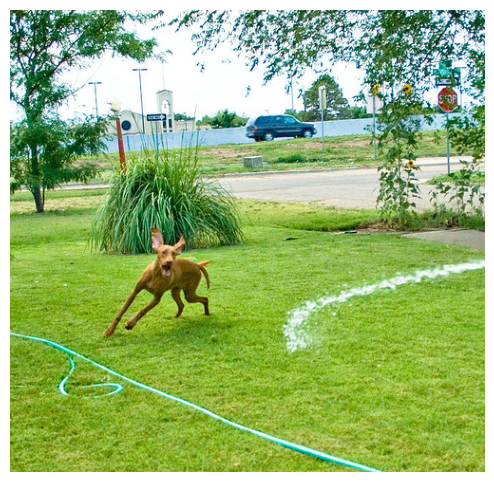

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

image_name = df.iloc[67]["image"]

image_path = os.path.join(image_dir, image_name)

image = Image.open(image_path)

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

In [ ]:
df[df["image"] == image_name]["caption"].tolist()

['A brown dog chases the water from a sprinkler on a lawn .',
 'a brown dog plays with the hose .',
 'A brown dog running on a lawn near a garden hose',
 'A dog is playing with a hose .',
 'Large brown dog running away from the sprinkler in the grass .']

#**Cleaning + Tokenizing**



In [ ]:
import os
import pandas as pd

IMAGE_DIR = "/content/flickr8k/Images"
CAPTION_FILE = "/content/flickr8k/captions.txt"

print("Images:", len(os.listdir(IMAGE_DIR)))

Images: 8091


In [ ]:
df = pd.read_csv(CAPTION_FILE)

df.head()

,image,caption
0,1000268201_693b08cb0e.jpg,A child in a pink dress is climbing up a set o...
1,1000268201_693b08cb0e.jpg,A girl going into a wooden building .
2,1000268201_693b08cb0e.jpg,A little girl climbing into a wooden playhouse .
3,1000268201_693b08cb0e.jpg,A little girl climbing the stairs to her playh...
4,1000268201_693b08cb0e.jpg,A little girl in a pink dress going into a woo...


In [ ]:
df.shape

(40455, 2)

#**V1**

##**Cleaning of text**

In [ ]:
import re

def clean_caption(text):
    text = text.lower()

    # Keeping only alphabetic characters and spaces
    text = re.sub(r"[^a-z\s]", "", text)

    # Removing extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [ ]:
caption = "A Dog is Running!"
print(clean_caption(caption))

a dog is running


In [ ]:
df["caption"] = df["caption"].apply(clean_caption)

df["caption"] = ("<start> "+ df["caption"] +" <end>")

In [ ]:
df.head()

,image,caption
0,1000268201_693b08cb0e.jpg,<start> a child in a pink dress is climbing up...
1,1000268201_693b08cb0e.jpg,<start> a girl going into a wooden building <end>
2,1000268201_693b08cb0e.jpg,<start> a little girl climbing into a wooden p...
3,1000268201_693b08cb0e.jpg,<start> a little girl climbing the stairs to h...
4,1000268201_693b08cb0e.jpg,<start> a little girl in a pink dress going in...


##**Building Vocab**

In [ ]:
from collections import Counter

counter = Counter()

for caption in df["caption"]:
  counter.update(caption.split())

In [ ]:
counter.most_common(20)

[('a', 62986),
 ('<start>', 40455),
 ('<end>', 40455),
 ('in', 18974),
 ('the', 18418),
 ('on', 10743),
 ('is', 9345),
 ('and', 8851),
 ('dog', 8136),
 ('with', 7765),
 ('man', 7265),
 ('of', 6713),
 ('two', 5638),
 ('white', 3940),
 ('black', 3832),
 ('boy', 3581),
 ('are', 3504),
 ('woman', 3402),
 ('girl', 3328),
 ('to', 3173)]

In [ ]:
VOCAB_SIZE = 5000

special_tokens = ["<pad>", "<start>", "<end>", "<unk>"]

words = [word for word, count in counter.most_common(VOCAB_SIZE - len(special_tokens))]

vocab = special_tokens + words

In [ ]:
word_to_idx = {word: idx for idx, word in enumerate(vocab)}
idx_to_word = {idx: word for word, idx in word_to_idx.items()}

In [ ]:
print(word_to_idx["dog"])
print(idx_to_word[5])

12
<start>


In [ ]:
def caption_to_indices(caption):
  tokens = caption.split()

  indices = [
      word_to_idx.get(word, word_to_idx["<unk>"])
      for word in tokens
  ]

  return indices

In [ ]:
sample_caption = df.iloc[0]["caption"]

print(sample_caption)
print(caption_to_indices(sample_caption))

<start> a child in a pink dress is climbing up a set of stairs in an entry way <end>
[5, 4, 45, 7, 4, 93, 173, 10, 122, 56, 4, 398, 15, 395, 7, 31, 3, 696, 6]


In [ ]:
len(vocab)

5000

##**Building_architecture[LSTM & ResNet50]**

In [ ]:
import torch
import torch.nn as nn

embedding = nn.Embedding(
    num_embeddings=len(vocab),
    embedding_dim=256,
    padding_idx=word_to_idx["<pad>"]
)

In [ ]:
len(vocab)

5000

In [ ]:
import torchvision.models as models

resnet = models.resnet50(weights="DEFAULT")

In [ ]:
#removing final classification Layer

resnet.fc = nn.Identity()

In [ ]:
print(resnet)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [ ]:
#Freezing ResNet

for param in resnet.parameters():
    param.requires_grad = False

In [ ]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [ ]:
from PIL import Image

image = Image.open(
    os.path.join(IMAGE_DIR, image_name)
).convert("RGB")

image_tensor = transform(image)

In [ ]:
image_tensor = image_tensor.unsqueeze(0)

print(image_tensor.shape)

torch.Size([1, 3, 224, 224])


In [ ]:
with torch.no_grad():
    image_features = resnet(image_tensor)

print(image_features.shape)

torch.Size([1, 2048])


In [ ]:
class ImageCaptioningModel(nn.Module):

  def _init_(
      self,
      vocab_size,
      embed_dim=256,
      hidden_dim=512,
      feature_dim=2048
  ):

    super().__init__()

    self.embedding = nn.Embedding(
        vocab_size,
        embed_dim,
        padding_idx=0
    )

    self.feature_projection = nn.Linear(
        feature_dim,
        hidden_dim
    )

    self.lstm = nn.LSTM(
        input_size=embed_dim,
        hidden_size=hidden_dim,
        batch_first=True
    )

    self.fc = nn.Linear(
        hidden_dim,
        vocab_size
    )

##**Data_Loading**

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import os

In [ ]:
class FlickrDataset(Dataset):

    def __init__(self, dataframe, image_dir, word_to_idx, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.word_to_idx = word_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        # Get image filename
        image_name = self.dataframe.iloc[index]["image"]

        # Get caption
        caption = self.dataframe.iloc[index]["caption"]

        # Build image path
        image_path = os.path.join(self.image_dir, image_name)

        # Open image
        image = Image.open(image_path).convert("RGB")

        # Apply CNN preprocessing
        if self.transform:
            image = self.transform(image)

        # Convert caption into token IDs
        caption_ids = [
            self.word_to_idx.get(
                word,
                self.word_to_idx["<unk>"]
            )
            for word in caption.split()
        ]

        caption_ids = torch.tensor(
            caption_ids,
            dtype=torch.long
        )

        return image, caption_ids

In [ ]:
dataset = FlickrDataset(
    dataframe=df,
    image_dir=IMAGE_DIR,
    word_to_idx=word_to_idx,
    transform=transform
)

In [ ]:
print("Dataset size:", len(dataset))

Dataset size: 40455


In [ ]:
image, caption_ids = dataset[0]

print("Image shape:", image.shape)
print("Caption IDs:", caption_ids)

Image shape: torch.Size([3, 224, 224])
Caption IDs: tensor([  5,   4,  45,   7,   4,  93, 173,  10, 122,  56,   4, 398,  15, 395,
          7,  31,   3, 696,   6])


In [ ]:
caption_words = [
    idx_to_word[idx.item()]
    for idx in caption_ids
]

print(caption_words)

['<start>', 'a', 'child', 'in', 'a', 'pink', 'dress', 'is', 'climbing', 'up', 'a', 'set', 'of', 'stairs', 'in', 'an', '<unk>', 'way', '<end>']


##**Padding_before_training**

In [ ]:
from torch.nn.utils.rnn import pad_sequence

In [ ]:
def collate_fn(batch):

    images, captions = zip(*batch)

    # Stacking images
    images = torch.stack(images)

    # Pad captions
    captions = pad_sequence(
        captions,
        batch_first=True,
        padding_value=word_to_idx["<pad>"]
    )

    return images, captions

In [ ]:
BATCH_SIZE = 32

dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

In [ ]:
images, captions = next(iter(dataloader))

print("Images shape:", images.shape)
print("Captions shape:", captions.shape)

Images shape: torch.Size([32, 3, 224, 224])
Captions shape: torch.Size([32, 20])


In [ ]:
for token_id in captions[0]:

    word = idx_to_word[token_id.item()]

    print(word, end=" ")

<start> a young inline skater balances with outstretched arms as he skates over the pavement <end> <pad> <pad> <pad> <pad> 

##**Combining_Architectures**

In [ ]:
feature_to_h = nn.Linear(2048, 512)
feature_to_c = nn.Linear(2048, 512)

In [ ]:
class CNN_LSTM(nn.Module):

    def __init__(
        self,
        cnn,
        vocab_size,
        embed_dim=256,
        hidden_dim=512
    ):
        super().__init__()

        # 1. Existing CNN

        self.cnn = cnn

        # 2. Word Embedding

        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embed_dim,
            padding_idx=word_to_idx["<pad>"]
        )


        # 3. CNN features → initial h0

        self.feature_to_h = nn.Linear(
            2048,
            hidden_dim
        )


        # 4. CNN features → initial c0

        self.feature_to_c = nn.Linear(
            2048,
            hidden_dim
        )


        # 5. LSTM

        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )


        # 6. LSTM → vocabulary

        self.fc = nn.Linear(
            hidden_dim,
            vocab_size
        )


    # FORWARD PASS

    def forward(self, images, captions):

        # 1. Image → CNN
        features = self.cnn(images)

        # Shape:
        # [B, 2048]


        # 2. Image features → initial hidden state
        h0 = self.feature_to_h(features)

        # [B, 512]


        # 3. Image features → initial cell state
        c0 = self.feature_to_c(features)

        # [B, 512]


        # 4. LSTM expects:
        # [num_layers, batch_size, hidden_dim]

        h0 = h0.unsqueeze(0)
        c0 = c0.unsqueeze(0)

        # [1, B, 512]


        # 5. Remove <END> from the input caption
        captions_input = captions[:, :-1]

        # Example:
        #
        # <start> a dog is running <end>
        #
        # becomes:
        #
        # <start> a dog is running


        # 6. Convert word IDs → embeddings
        embeddings = self.embedding(captions_input)

        # [B, T-1, 256]


        # 7. Feed embeddings + image-derived states into LSTM
        lstm_output, _ = self.lstm(
            embeddings,
            (h0, c0)
        )

        # [B, T-1, 512]


        # 8. Convert LSTM output → vocabulary scores
        outputs = self.fc(lstm_output)

        # [B, T-1, vocab_size]

        return outputs

In [ ]:
model = CNN_LSTM(
    cnn=resnet,
    vocab_size=len(vocab),
    embed_dim=256,
    hidden_dim=512
)

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print(device)

cuda


In [ ]:
images, captions = next(iter(dataloader))

In [ ]:
images = images.to(device)
captions = captions.to(device)

In [ ]:
outputs = model(images, captions)

In [ ]:
print("Images :", images.shape)
print("Captions:", captions.shape)
print("Outputs :", outputs.shape)

Images : torch.Size([32, 3, 224, 224])
Captions: torch.Size([32, 24])
Outputs : torch.Size([32, 23, 5000])


##**Computing Loss Fxn + Optimizer**

In [ ]:
outputs = model(images, captions)

print(outputs.shape)

torch.Size([32, 23, 5000])


In [ ]:
captions_input = captions[:, :-1]

In [ ]:
targets = captions[:, 1:]

In [ ]:
PAD_IDX = word_to_idx["<pad>"]

In [ ]:
criterion = nn.CrossEntropyLoss(
    ignore_index=PAD_IDX
)

In [ ]:
targets = captions[:, 1:]

outputs_flat = outputs.reshape(
    -1,
    outputs.size(2)
)

targets_flat = targets.reshape(-1)

loss = criterion(
    outputs_flat,
    targets_flat
)

print("Loss:", loss.item())

Loss: 8.506051063537598


In [ ]:
optimizer = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=1e-4
)

In [ ]:
num_epochs = 5

for epoch in range(num_epochs):

    model.train()

    total_loss = 0

    for images, captions in dataloader:

        # Move data to GPU
        images = images.to(device)
        captions = captions.to(device)


        # 1. Clearing old gradients

        optimizer.zero_grad()


        # 2. Forward pass

        outputs = model(images, captions)


        # 3. Targets

        targets = captions[:, 1:]

        # 4. Flatten

        outputs = outputs.reshape(
            -1,
            outputs.size(2)
        )

        targets = targets.reshape(-1)


        # 5. Calculating loss

        loss = criterion(
            outputs,
            targets
        )


        # 6. Backpropagation

        loss.backward()


        # 7. Update parameters

        optimizer.step()


        # 8. Store loss

        total_loss += loss.item()

    avg_loss = total_loss / len(dataloader)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {avg_loss:.4f}"
    )

Epoch [1/5] Loss: 4.4678
Epoch [2/5] Loss: 3.6130
Epoch [3/5] Loss: 3.2860
Epoch [4/5] Loss: 3.0711
Epoch [5/5] Loss: 2.9132


In [ ]:
torch.save(
    model.state_dict(),
    "/content/cnn_lstm_flickr8k.pth"
)

print("Model saved!")

Model saved!


In [ ]:
# model.load_state_dict(
#     torch.load(
#         "/content/cnn_lstm_flickr8k.pth",
#         map_location=device
#     )
# )

# model.eval()

##**Evaluation**

In [ ]:
model.eval()

CNN_LSTM(
  (cnn): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Sequential(
          (0)

In [ ]:
def generate_caption(model, image, max_length=30):

    model.eval()


    # 1. Preparing image

    image = transform(image)
    image = image.unsqueeze(0).to(device)

    # [1, 3, 224, 224]

    # 2. Extract image features

    with torch.no_grad():
        features = model.cnn(image)

        # [1, 2048]



        # 3. Create initial LSTM states

        h = model.feature_to_h(features)
        c = model.feature_to_c(features)

        # [1, 512]

        h = h.unsqueeze(0)
        c = c.unsqueeze(0)

        # [1, 1, 512]



        # 4. Start caption

        current_word = word_to_idx["<start>"]

        generated_words = ["<start>"]



        # 5. Generating one word at a time

        for _ in range(max_length):

            # Word ID → tensor
            word_tensor = torch.tensor(
                [current_word],
                dtype=torch.long,
                device=device
            )

            # [1]


            # Add sequence dimension
            word_tensor = word_tensor.unsqueeze(1)

            # [1, 1]


            # Word ID → embedding
            embedding = model.embedding(word_tensor)

            # [1, 1, 256]


            # LSTM
            output, (h, c) = model.lstm(
                embedding,
                (h, c)
            )

            # [1, 1, 512]


            # Vocabulary logits
            logits = model.fc(output)

            # [1, 1, vocab_size]


            # Select most likely word
            predicted_id = logits.argmax(
                dim=-1
            ).item()


            # Convert ID → word
            predicted_word = idx_to_word[
                predicted_id
            ]


            # Stop if END token
            if predicted_word == "<end>":
                break


            # Add word
            generated_words.append(
                predicted_word
            )


            # Feed prediction back
            current_word = predicted_id


    return generated_words

In [ ]:
image_name = df.iloc[112]["image"]

image_path = os.path.join(
    IMAGE_DIR,
    image_name
)

image = Image.open(image_path).convert("RGB")

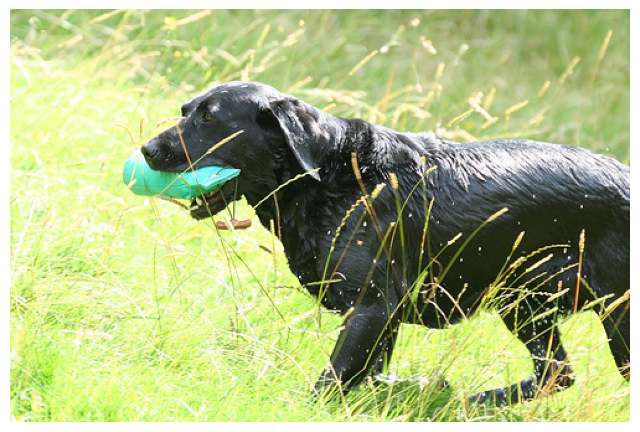

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

In [ ]:
caption = generate_caption(
    model,
    image
)

print("Generated caption:")
print(" ".join(caption))

Generated caption:
<start> a black dog is running through a grassy field


In [ ]:
real_captions = df[
    df["image"] == image_name
]["caption"].tolist()

for caption in real_captions:
    print(caption)

<start> a black dog carries a green toy in his mouth as he walks through the grass <end>
<start> a black dog carrying something through the grass <end>
<start> a black dog has a blue toy in its mouth <end>
<start> a dog in grass with a blue item in his mouth <end>
<start> a wet black dog is carrying a green toy through the grass <end>


#**V2**

In [ ]:
import torchvision.models as models
import torch
import torch.nn as nn

In [ ]:
resnet_base = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

In [ ]:
resnet_spatial = nn.Sequential(
    *list(resnet_base.children())[:-2]
)

In [ ]:
for param in resnet_spatial.parameters():
    param.requires_grad = False

In [ ]:
resnet_spatial = resnet_spatial.to(device)

In [ ]:
resnet_spatial.eval()

Sequential(
  (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (4): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)


In [ ]:
images, captions = next(iter(dataloader))

images = images.to(device)

In [ ]:
with torch.no_grad():
    features = resnet_spatial(images)

print(features.shape)

torch.Size([32, 2048, 7, 7])


In [ ]:
B, C, H, W = features.shape

features = features.permute(
    0, 2, 3, 1
)

features = features.view(
    B,
    H * W,
    C
)

print(features.shape)

torch.Size([32, 49, 2048])


In [ ]:
class BahdanauAttention(nn.Module):

    def __init__(
        self,
        feature_dim=2048,
        hidden_dim=512,
        attention_dim=256
    ):
        super().__init__()

        self.feature_projection = nn.Linear(
            feature_dim,
            attention_dim
        )

        self.hidden_projection = nn.Linear(
            hidden_dim,
            attention_dim
        )

        self.score = nn.Linear(
            attention_dim,
            1
        )

    def forward(self, features, hidden):

        # features:
        # [B, 49, 2048]

        # hidden:
        # [B, 512]

        feature_energy = self.feature_projection(
            features
        )

        # [B, 49, 256]

        hidden_energy = self.hidden_projection(
            hidden
        )

        # [B, 256]

        hidden_energy = hidden_energy.unsqueeze(1)

        # [B, 1, 256]

        energy = torch.tanh(
            feature_energy + hidden_energy
        )

        # [B, 49, 256]

        scores = self.score(
            energy
        )

        # [B, 49, 1]

        scores = scores.squeeze(-1)

        # [B, 49]

        attention_weights = torch.softmax(
            scores,
            dim=1
        )

        # [B, 49]

        context = torch.sum(
            features * attention_weights.unsqueeze(-1),
            dim=1
        )

        # [B, 2048]

        return context, attention_weights

##**Running Attention Features**

In [ ]:
# Get one batch
images, captions = next(iter(dataloader))

images = images.to(device)

# Extract spatial CNN features
with torch.no_grad():
    features = resnet_spatial(images)

print("CNN output:", features.shape)

CNN output: torch.Size([32, 2048, 7, 7])


In [ ]:
B, C, H, W = features.shape

features = features.permute(0, 2, 3, 1)
features = features.reshape(B, H * W, C)

print("Spatial features:", features.shape)

Spatial features: torch.Size([32, 49, 2048])


In [ ]:
attention = BahdanauAttention(
    feature_dim=2048,
    hidden_dim=512,
    attention_dim=256
).to(device)

In [ ]:
hidden = torch.randn(
    B,
    512,
    device=device
)

print("Hidden:", hidden.shape)

Hidden: torch.Size([32, 512])


In [ ]:
context, attention_weights = attention(
    features,
    hidden
)

print("Context:", context.shape)
print("Attention weights:", attention_weights.shape)

Context: torch.Size([32, 2048])
Attention weights: torch.Size([32, 49])


In [ ]:
weight_sum = attention_weights.sum(dim=1)

print(weight_sum[:5])

tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000], device='cuda:0',
       grad_fn=<SliceBackward0>)


In [ ]:
print(
    "Maximum error:",
    torch.abs(weight_sum - 1).max().item()
)

Maximum error: 1.1920928955078125e-07


In [ ]:
weights = attention_weights[0]

print(weights)

tensor([0.0233, 0.0155, 0.0157, 0.0167, 0.0203, 0.0179, 0.0220, 0.0142, 0.0150,
        0.0175, 0.0186, 0.0160, 0.0182, 0.0150, 0.0165, 0.0159, 0.0169, 0.0189,
        0.0177, 0.0187, 0.0148, 0.0202, 0.0213, 0.0205, 0.0205, 0.0257, 0.0297,
        0.0216, 0.0194, 0.0202, 0.0185, 0.0199, 0.0266, 0.0145, 0.0236, 0.0222,
        0.0232, 0.0211, 0.0277, 0.0207, 0.0201, 0.0229, 0.0231, 0.0249, 0.0229,
        0.0267, 0.0289, 0.0236, 0.0244], device='cuda:0',
       grad_fn=<SelectBackward0>)


In [ ]:
max_region = weights.argmax().item()

print("Most attended region:", max_region)
print("Attention:", weights[max_region].item())

Most attended region: 26
Attention: 0.029719240963459015


In [ ]:
attention_map = attention_weights[0].detach().cpu()
attention_map = attention_map.reshape(7, 7)

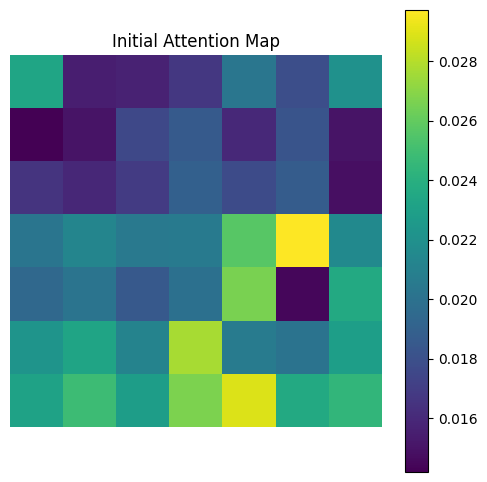

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.imshow(attention_map)
plt.colorbar()
plt.title("Initial Attention Map")
plt.axis("off")
plt.show()

In [ ]:
print("V2 ATTENTION TEST")

print("Spatial features :", features.shape)
print("Hidden state     :", hidden.shape)
print("Context vector   :", context.shape)
print("Attention weights :", attention_weights.shape)

print(
    "Weight sum       :",
    attention_weights[0].sum().item()
)

print(
    "Max attention    :",
    attention_weights[0].max().item()
)

print(
    "Min attention    :",
    attention_weights[0].min().item()
)

===== V2 ATTENTION TEST =====
Spatial features : torch.Size([32, 49, 2048])
Hidden state     : torch.Size([32, 512])
Context vector   : torch.Size([32, 2048])
Attention weights : torch.Size([32, 49])
Weight sum       : 1.0
Max attention    : 0.029719240963459015
Min attention    : 0.014185181818902493


##**Integrating (attention+old structure)**

In [ ]:
class CNN_Attention_LSTM(nn.Module):

    def __init__(
        self,
        cnn,
        attention,
        vocab_size,
        embed_dim=256,
        hidden_dim=512
    ):
        super().__init__()

        self.cnn = cnn
        self.attention = attention

        # Word → embedding
        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=word_to_idx["<pad>"]
        )

        # Image feature → initial LSTM states
        self.feature_to_h = nn.Linear(
            2048,
            hidden_dim
        )

        self.feature_to_c = nn.Linear(
            2048,
            hidden_dim
        )

        # Attention context: 2048 → 256
        self.context_projection = nn.Linear(
            2048,
            embed_dim
        )

        # Word embedding 256 + context 256
        self.lstm = nn.LSTM(
            input_size=embed_dim * 2,
            hidden_size=hidden_dim,
            batch_first=True
        )

        # Hidden state → vocabulary
        self.fc = nn.Linear(
            hidden_dim,
            vocab_size
        )
    def forward(self, images, captions):


        # 1. Extract spatial features

        features = self.cnn(images)

        # [B, 2048, 7, 7]

        B, C, H, W = features.shape

        # Convert to spatial regions
        features = features.permute(
            0, 2, 3, 1
        )

        features = features.reshape(
            B,
            H * W,
            C
        )

        # [B, 49, 2048]



        # 2. Initial LSTM states

        global_features = features.mean(dim=1)

        # [B, 2048]

        h = self.feature_to_h(
            global_features
        )

        c = self.feature_to_c(
            global_features
        )

        h = h.unsqueeze(0)
        c = c.unsqueeze(0)

        # [1, B, 512]



        # 3. Input caption

        captions_input = captions[:, :-1]

        # [B, T-1]



        # 4. Word embeddings

        embeddings = self.embedding(
            captions_input
        )

        # [B, T-1, 256]



        # 5. Generate each timestep

        outputs = []

        for t in range(
            embeddings.size(1)
        ):

            # Current word embedding
            word_embedding = embeddings[:, t, :]

            # [B, 256]


            # Attention
            context, attention_weights = self.attention(
                features,
                h[-1]
            )

            # context:
            # [B, 2048]

            # attention_weights:
            # [B, 49]


            # Project visual context
            context = self.context_projection(
                context
            )

            # [B, 256]


            # Combine language + vision
            lstm_input = torch.cat(
                [word_embedding, context],
                dim=1
            )

            # [B, 512]

            lstm_input = lstm_input.unsqueeze(1)

            # [B, 1, 512]


            # LSTM
            output, (h, c) = self.lstm(
                lstm_input,
                (h, c)
            )

            # [B, 1, 512]


            # Vocabulary prediction
            logits = self.fc(
                output.squeeze(1)
            )

            # [B, vocab_size]

            outputs.append(logits)

        # [B, T-1, vocab_size]
        outputs = torch.stack(
            outputs,
            dim=1
        )

        return outputs

    def train(self, mode=True):
      super().train(mode)

      # Keep frozen CNN in evaluation mode
      self.cnn.eval()

      return self

In [ ]:
model_v2 = CNN_Attention_LSTM(
    cnn=resnet_spatial,
    attention=attention,
    vocab_size=len(vocab),
    embed_dim=256,
    hidden_dim=512
)

In [ ]:
model_v2 = model_v2.to(device)

In [ ]:
images, captions = next(iter(dataloader))

images = images.to(device)
captions = captions.to(device)

In [ ]:
model_v2.eval()

with torch.no_grad():

    outputs = model_v2(
        images,
        captions
    )

print("Images :", images.shape)
print("Captions:", captions.shape)
print("Outputs :", outputs.shape)

Images : torch.Size([32, 3, 224, 224])
Captions: torch.Size([32, 19])
Outputs : torch.Size([32, 18, 5000])


##**Training_V2**

In [ ]:
PAD_IDX = word_to_idx["<pad>"]

criterion_v2 = nn.CrossEntropyLoss(
    ignore_index=PAD_IDX
)

optimizer_v2 = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        model_v2.parameters()
    ),
    lr=1e-4
)

In [ ]:
num_epochs = 5

for epoch in range(num_epochs):

    model_v2.train()

    total_loss = 0

    for images, captions in dataloader:

        images = images.to(device)
        captions = captions.to(device)

        # Forward pass
        outputs = model_v2(
            images,
            captions
        )

        # Removing <start> from input
        # Removing final token from target
        targets = captions[:, 1:]

        # Flatten
        outputs_flat = outputs.reshape(
            -1,
            outputs.size(-1)
        )

        targets_flat = targets.reshape(-1)

        # Loss
        loss = criterion_v2(
            outputs_flat,
            targets_flat
        )

        # Backpropagation
        optimizer_v2.zero_grad()

        loss.backward()

        # Prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(
            model_v2.parameters(),
            max_norm=5.0
        )

        optimizer_v2.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(dataloader)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {avg_loss:.4f}"
    )

Epoch [1/5] Loss: 4.4933
Epoch [2/5] Loss: 3.6048
Epoch [3/5] Loss: 3.2477
Epoch [4/5] Loss: 3.0101
Epoch [5/5] Loss: 2.8297


In [ ]:
torch.save(
    model_v2.state_dict(),
    "/content/cnn_attention_lstm_flickr8k.pth"
)

print("V2 model saved.")

V2 model saved.


##**V2_Inference**

In [ ]:
def generate_caption_v2(model, image, max_length=30):

    model.eval()

    image = transform(image)
    image = image.unsqueeze(0).to(device)

    with torch.no_grad():

        # CNN → spatial features
        features = model.cnn(image)

        B, C, H, W = features.shape

        features = features.permute(0, 2, 3, 1)
        features = features.reshape(
            B,
            H * W,
            C
        )
        # [1, 49, 2048]

        # Initialize LSTM states
        global_features = features.mean(dim=1)

        h = model.feature_to_h(global_features)
        c = model.feature_to_c(global_features)

        h = h.unsqueeze(0)
        c = c.unsqueeze(0)

        current_word = word_to_idx["<start>"]

        generated_words = ["<start>"]

        attention_history = []

        for _ in range(max_length):

            # Current word
            word_tensor = torch.tensor(
                [current_word],
                dtype=torch.long,
                device=device
            ).unsqueeze(1)

            embedding = model.embedding(
                word_tensor
            )

            # Attention
            context, attention_weights = model.attention(
                features,
                h[-1]
            )

            attention_history.append(
                attention_weights.squeeze(0).cpu()
            )

            # Project context
            context = model.context_projection(
                context
            )

            # Word + visual context
            lstm_input = torch.cat(
                [embedding.squeeze(1), context],
                dim=1
            )

            lstm_input = lstm_input.unsqueeze(1)

            # LSTM
            output, (h, c) = model.lstm(
                lstm_input,
                (h, c)
            )

            # Predict next token
            logits = model.fc(
                output.squeeze(1)
            )

            predicted_id = logits.argmax(
                dim=-1
            ).item()

            predicted_word = idx_to_word[
                predicted_id
            ]

            if predicted_word == "<end>":
                break

            generated_words.append(
                predicted_word
            )

            current_word = predicted_id

    return generated_words, attention_history

In [ ]:
caption, attention_history = generate_caption_v2(
    model_v2,
    image
)

print(" ".join(caption))

<start> a black dog with a red collar is running through the grass


In [ ]:
print(
    "Number of words:",
    len(attention_history)
)

print(
    "Attention shape:",
    attention_history[0].shape
)

Number of words: 13
Attention shape: torch.Size([49])


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def show_attention(
    image,
    caption,
    attention_history
):

    plt.figure(figsize=(15, 10))

    num_words = min(
        len(caption),
        len(attention_history)
    )

    for i in range(num_words):

        attention_map = attention_history[i]

        attention_map = attention_map.reshape(
            7, 7
        ).numpy()

        attention_map = np.array(
            attention_map
        )

        plt.subplot(
            3,
            6,
            i + 1
        )

        plt.imshow(image)

        plt.imshow(
            attention_map,
            alpha=0.5,
            extent=(
                0,
                image.width,
                image.height,
                0
            ),
            cmap="jet"
        )

        plt.title(caption[i])

        plt.axis("off")

    plt.tight_layout()
    plt.show()

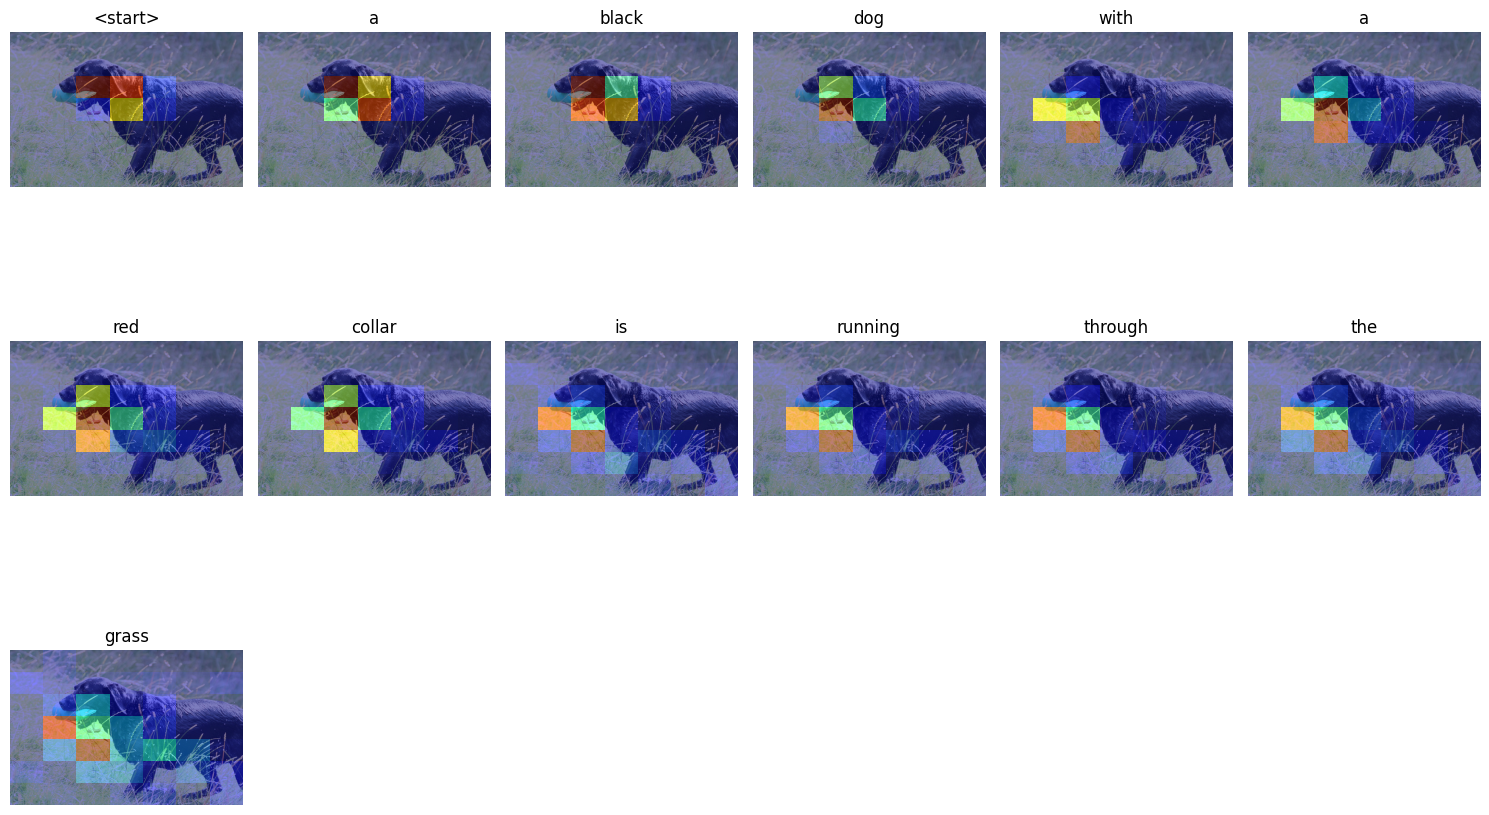

In [ ]:
show_attention(
    image,
    caption,
    attention_history
)

In [ ]:
# Pick one image from your dataset
images, captions = next(iter(dataloader))

# Move image batch to CPU for visualization
test_image = images[0].cpu()

# If your dataloader images are normalized, unnormalize them
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

test_image = test_image * std + mean
test_image = torch.clamp(test_image, 0, 1)

# Convert tensor → PIL
from torchvision.transforms.functional import to_pil_image

test_image_pil = to_pil_image(test_image)

# Generate caption + attention
caption, attention_history = generate_caption_v2(
    model_v2,
    test_image_pil
)

print("Generated Caption:")
print(" ".join(caption))

print("\nAttention steps:", len(attention_history))
print("Attention shape:", attention_history[0].shape)

Generated Caption:
<start> a tennis player in a white shirt and white shirt is holding a tennis ball

Attention steps: 16
Attention shape: torch.Size([49])


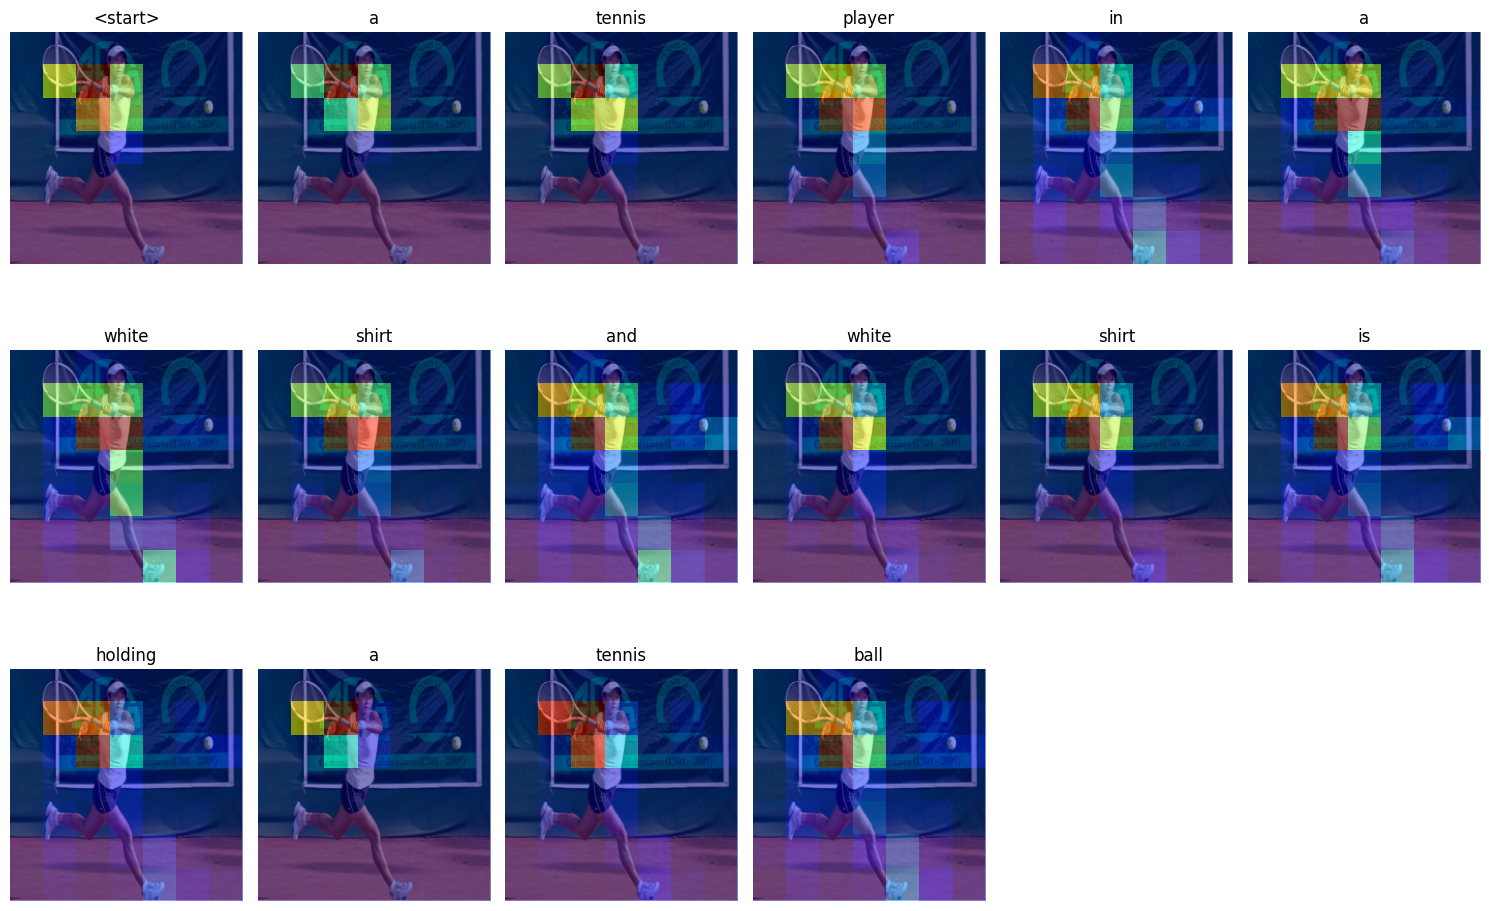

In [ ]:
show_attention(
    test_image_pil,
    caption,
    attention_history
)

#**V3**

In [ ]:
for param in resnet_spatial.parameters():
    param.requires_grad = False

resnet_spatial.eval()

Sequential(
  (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (4): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)


In [ ]:
import torch
import torch.nn as nn


class CNN_Transformer(nn.Module):

    def __init__(
        self,
        cnn,
        vocab_size,
        d_model=512,
        nhead=8,
        num_layers=4,
        dim_feedforward=2048,
        dropout=0.1,
        max_length=50
    ):
        super().__init__()

        self.cnn = cnn

        self.d_model = d_model
        self.max_length = max_length

        # 2048-D CNN features → Transformer dimension
        self.feature_projection = nn.Linear(
            2048,
            d_model
        )

        # Visual positional embeddings
        self.image_position = nn.Parameter(
            torch.randn(1, 49, d_model)
        )

        # Word embedding
        self.embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=word_to_idx["<pad>"]
        )

        # Text positional embeddings
        self.text_position = nn.Parameter(
            torch.randn(1, max_length, d_model)
        )

        # Transformer decoder layer
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )

        # Transformer decoder
        self.transformer_decoder = nn.TransformerDecoder(
            decoder_layer,
            num_layers=num_layers
        )

        # Vocabulary prediction
        self.fc = nn.Linear(
            d_model,
            vocab_size
        )

    def train(self, mode=True):

        super().train(mode)

        # Keep frozen CNN in evaluation mode
        self.cnn.eval()

        return self

    def generate_causal_mask(self, size, device):

        mask = torch.triu(
            torch.ones(
                size,
                size,
                device=device
            ),
            diagonal=1
        )

        mask = mask.masked_fill(
            mask == 1,
            float("-inf")
        )

        return mask

    def forward(self, images, captions):


        # 1. CNN FEATURE EXTRACTION


        features = self.cnn(images)

        # [B, 2048, 7, 7]

        B, C, H, W = features.shape

        # Convert spatial map → visual tokens
        features = features.permute(
            0, 2, 3, 1
        )

        features = features.reshape(
            B,
            H * W,
            C
        )

        # [B, 49, 2048]

        # 2. PROJECT VISUAL FEATURES

        memory = self.feature_projection(
            features
        )

        # [B, 49, 512]

        memory = memory + self.image_position


        # 3. TEXT INPUT

        captions_input = captions[:, :-1]

        # [B, T-1]

        embeddings = self.embedding(
            captions_input
        )

        # [B, T-1, 512]

        T = embeddings.size(1)

        embeddings = embeddings + \
            self.text_position[:, :T, :]


        # 4. CAUSAL MASK

        causal_mask = self.generate_causal_mask(
            T,
            images.device
        )


        # 5. PADDING MASK

        padding_mask = (
            captions_input ==
            word_to_idx["<pad>"]
        )


        # 6. TRANSFORMER DECODER

        output = self.transformer_decoder(
            tgt=embeddings,
            memory=memory,
            tgt_mask=causal_mask,
            tgt_key_padding_mask=padding_mask
        )

        # [B, T-1, 512]

        # 7. WORD PREDICTION

        logits = self.fc(output)

        # [B, T-1, vocab_size]

        return logits

In [ ]:
model_v3 = CNN_Transformer(
    cnn=resnet_spatial,
    vocab_size=len(vocab),
    d_model=512,
    nhead=8,
    num_layers=4,
    dim_feedforward=2048,
    dropout=0.1,
    max_length=50
)

model_v3 = model_v3.to(device)

In [ ]:
images, captions = next(iter(dataloader))

images = images.to(device)
captions = captions.to(device)

model_v3.eval()

with torch.no_grad():

    outputs = model_v3(
        images,
        captions
    )

print("Images   :", images.shape)
print("Captions :", captions.shape)
print("Outputs  :", outputs.shape)

Images   : torch.Size([32, 3, 224, 224])
Captions : torch.Size([32, 20])
Outputs  : torch.Size([32, 19, 5000])


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/activation.py:1336: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(


##**Traning & loss optimization**

In [ ]:
PAD_IDX = word_to_idx["<pad>"]

criterion_v3 = nn.CrossEntropyLoss(
    ignore_index=PAD_IDX
)

optimizer_v3 = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        model_v3.parameters()
    ),
    lr=1e-4
)

In [ ]:
num_epochs = 5

for epoch in range(num_epochs):

    model_v3.train()

    total_loss = 0

    for images, captions in dataloader:

        images = images.to(device)
        captions = captions.to(device)

        # Forward

        outputs = model_v3(
            images,
            captions
        )

        # Target = next token

        targets = captions[:, 1:]

        # Flatten

        outputs_flat = outputs.reshape(
            -1,
            outputs.size(-1)
        )

        targets_flat = targets.reshape(-1)

        # Loss

        loss = criterion_v3(
            outputs_flat,
            targets_flat
        )

        # Backpropagation

        optimizer_v3.zero_grad()

        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model_v3.parameters(),
            max_norm=5.0
        )

        optimizer_v3.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(dataloader)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {avg_loss:.4f}"
    )

Epoch [1/5] Loss: 3.7041
Epoch [2/5] Loss: 2.8720
Epoch [3/5] Loss: 2.5290
Epoch [4/5] Loss: 2.2690
Epoch [5/5] Loss: 2.0432


In [ ]:
torch.save(
    model_v3.state_dict(),
    "/content/cnn_transformer_flickr8k.pth"
)

print("V3 model saved.")

V3 model saved.


##**Evaluation (Caption_Generator)**

In [ ]:
def generate_caption_v3(model, image, max_length=30):

    model.eval()

    image = transform(image)
    image = image.unsqueeze(0).to(device)

    with torch.no_grad():

        # CNN → visual tokens

        features = model.cnn(image)

        B, C, H, W = features.shape

        features = features.permute(
            0, 2, 3, 1
        )

        features = features.reshape(
            B,
            H * W,
            C
        )

        # [1, 49, 2048]


        # Project image features

        memory = model.feature_projection(
            features
        )

        memory = memory + model.image_position

        # [1, 49, 512]

        # Start token


        generated_ids = [
            word_to_idx["<start>"]
        ]

        generated_words = [
            "<start>"
        ]


        # Autoregressive generation

        for _ in range(max_length):

            tokens = torch.tensor(
                generated_ids,
                dtype=torch.long,
                device=device
            ).unsqueeze(0)

            # [1, T]

            embeddings = model.embedding(tokens)

            T = embeddings.size(1)

            embeddings = embeddings + \
                model.text_position[:, :T, :]

            # Causal mask
            causal_mask = model.generate_causal_mask(
                T,
                device
            )

            # Transformer decoder
            output = model.transformer_decoder(
                tgt=embeddings,
                memory=memory,
                tgt_mask=causal_mask
            )

            # Only use the final timestep
            logits = model.fc(
                output[:, -1, :]
            )

            predicted_id = logits.argmax(
                dim=-1
            ).item()

            predicted_word = idx_to_word[
                predicted_id
            ]

            # Stop generation
            if predicted_word == "<end>":
                break

            generated_ids.append(
                predicted_id
            )

            generated_words.append(
                predicted_word
            )

    return generated_words

In [ ]:
caption_v3 = generate_caption_v3(
    model_v3,
    test_image_pil
)

print("V3 Generated Caption:")
print(" ".join(caption_v3))

V3 Generated Caption:
<start> a woman in a white shirt and black shorts is playing tennis


In [ ]:
caption_v1 = generate_caption(
    model,
    test_image_pil
)

caption_v2, _ = generate_caption_v2(
    model_v2,
    test_image_pil
)

caption_v3 = generate_caption_v3(
    model_v3,
    test_image_pil
)

print("V1:", " ".join(caption_v1))
print("V2:", " ".join(caption_v2))
print("V3:", " ".join(caption_v3))

V1: <start> a tennis player in a white shirt is playing with a tennis ball
V2: <start> a tennis player in a white shirt and white shirt is holding a tennis ball
V3: <start> a woman in a white shirt and black shorts is playing tennis


#**Comparision**

In [ ]:
!pip install nltk

In [ ]:
from nltk.translate.bleu_score import sentence_bleu

In [ ]:
def clean_caption(caption):

    return [
        word for word in caption
        if word not in ["<start>", "<end>", "<pad>"]
    ]

In [ ]:
sample = dataset[0]

print(type(sample))
print(sample)

<class 'tuple'>
(tensor([[[-0.7137, -0.2171, -0.1314,  ..., -2.0494, -2.0152, -2.0152],
         [-0.7650, -0.1828, -0.0801,  ..., -1.9809, -1.9980, -1.9124],
         [-0.7993, -0.1143, -0.0458,  ..., -1.9809, -1.9980, -1.9467],
         ...,
         [ 1.0673,  0.4508,  0.8104,  ...,  1.5125,  0.7077,  0.7077],
         [ 0.8961,  0.9132,  1.6495,  ...,  1.4783,  0.7591,  0.7591],
         [ 1.4269,  1.4612,  1.0844,  ...,  1.3927,  0.7419,  0.7762]],

        [[-0.5126,  0.2052,  0.3102,  ..., -1.9832, -1.9307, -1.8957],
         [-0.5651,  0.2227,  0.3803,  ..., -1.8782, -1.8606, -1.6681],
         [-0.6527,  0.2752,  0.4328,  ..., -1.8782, -1.8081, -1.6506],
         ...,
         [-0.1450, -0.6352,  0.1001,  ...,  1.8333,  1.2031,  1.1856],
         [-0.3550,  0.2227,  0.9230,  ...,  1.7808,  1.1856,  1.1856],
         [ 0.1702,  0.5553,  0.1001,  ...,  1.7108,  1.1856,  1.1856]],

        [[-0.1138,  0.3742,  0.4091,  ..., -1.7522, -1.7347, -1.7173],
         [-0.2010,  0.4439, 

In [ ]:
# Getting one sample directly from dataset
test_image, test_caption = dataset[0]

print("Image shape:", test_image.shape)
print("Caption shape:", test_caption.shape)

Image shape: torch.Size([3, 224, 224])
Caption shape: torch.Size([19])


In [ ]:
reference = [
    idx_to_word[idx.item()]
    for idx in test_caption
]

reference = clean_caption(reference)

print("REFERENCE:")
print(" ".join(reference))

REFERENCE:
a child in a pink dress is climbing up a set of stairs in an <unk> way


In [ ]:
mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)

display_image = test_image.cpu() * std + mean
display_image = torch.clamp(
    display_image,
    0,
    1
)

from torchvision.transforms.functional import to_pil_image

test_image_pil = to_pil_image(
    display_image
)

In [ ]:
generated_v1 = clean_caption(
    generate_caption(
        model,
        test_image_pil
    )
)

generated_v2_raw, _ = generate_caption_v2(
    model_v2,
    test_image_pil
)

generated_v2 = clean_caption(
    generated_v2_raw
)

generated_v3 = clean_caption(
    generate_caption_v3(
        model_v3,
        test_image_pil
    )
)

In [ ]:
print("REFERENCE:")
print(" ".join(reference))

print("\nV1:")
print(" ".join(generated_v1))

print("\nV2:")
print(" ".join(generated_v2))

print("\nV3:")
print(" ".join(generated_v3))

REFERENCE:
a child in a pink dress is climbing up a set of stairs in an <unk> way

V1:
a little girl in a pink shirt is sitting on a bench

V2:
a little girl in a pink dress is sitting on a bench

V3:
a little girl in a pink dress is standing in front of a wooden wooden wooden door


In [ ]:
bleu_v1 = sentence_bleu(
    [reference],
    generated_v1
)

bleu_v2 = sentence_bleu(
    [reference],
    generated_v2
)

bleu_v3 = sentence_bleu(
    [reference],
    generated_v3
)

print(f"V1 BLEU: {bleu_v1:.4f}")
print(f"V2 BLEU: {bleu_v2:.4f}")
print(f"V3 BLEU: {bleu_v3:.4f}")

V1 BLEU: 0.0000
V2 BLEU: 0.2273
V3 BLEU: 0.2480
